# 01 — Data Extraction and Preprocessing

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.compute as pc
import pyarrow.parquet as pq

from src import config
from src.viz import MUTED_FILL, SERIES, TEXT_MUTED, apply_style, save

apply_style()
pd.set_option("display.max_colwidth", 80)

## 1. Ekstraksi Data

Sumber: rilis DBLP 2026-11-01 ([doi:10.4230/dblp.xml.2026-11-01](https://doi.org/10.4230/dblp.xml.2026-11-01)),
diunduh pada 18 November 2026. Sel berikut mengunduh data dengan verifikasi MD5 dan mengekstrak
record `inproceedings` ke Parquet, hanya jika hasilnya belum tersedia.

In [2]:
from src.download import download
from src.extract import extract

if not config.INPROC_RAW.exists():
    download()
    extract()

print(config.INPROC_RAW, f"{config.INPROC_RAW.stat().st_size / 1e6:,.0f} MB")

C:\Users\Alfansya\dblp-data\inproceedings-2026-11-01.parquet 406 MB


## 2. Data Understanding (Task 1 poin 1)

### 2.1 Struktur Dataset

Contoh satu record `inproceedings` hasil ekstraksi.

In [3]:
example = pq.read_table(config.INPROC_RAW, filters=[("key", "==", "conf/cvpr/HeZRS16")]).to_pylist()
pd.Series(example[0]) if example else "Record contoh tidak ditemukan pada rilis ini."

key                                                      conf/cvpr/HeZRS16
mdate                                                           2023-03-24
publtype                                                              None
title                        Deep Residual Learning for Image Recognition.
authors      [Kaiming He, Xiangyu Zhang 0005, Shaoqing Ren, Jian Sun 0001]
year                                                                  2016
booktitle                                                             CVPR
crossref                                                    conf/cvpr/2016
dtype: object

### 2.2 Jenis Publikasi

In [4]:
types = pd.read_csv(config.TABLES_DIR / "dblp_record_types.csv")
types["pct"] = (100 * types["n_records"] / types["n_records"].sum()).round(2)
print(f"Total record: {types['n_records'].sum():,}")
types

Total record: 13,073,341


,record_type,n_records,pct
0,article,4500269,34.42
1,www,4230393,32.36
2,inproceedings,3994940,30.56
3,phdthesis,158401,1.21
4,incollection,71247,0.54
5,proceedings,65785,0.50
6,data,30631,0.23
7,book,21648,0.17
8,mastersthesis,27,0.00


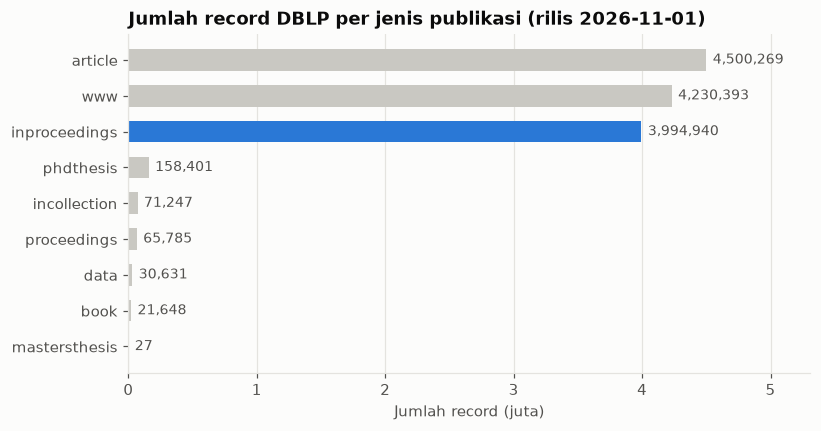

In [5]:
t = types.sort_values("n_records")
colors = [SERIES[0] if r == "inproceedings" else MUTED_FILL for r in t["record_type"]]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(t["record_type"], t["n_records"] / 1e6, color=colors, height=0.6)
for y, v in enumerate(t["n_records"]):
    ax.text(v / 1e6 + 0.05, y, f"{v:,}", va="center", fontsize=9, color=TEXT_MUTED)
ax.set_xlabel("Jumlah record (juta)")
ax.set_title("Jumlah record DBLP per jenis publikasi (rilis 2026-11-01)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, t["n_records"].max() / 1e6 * 1.18)
save(fig, "01_record_types")
plt.show()

### 2.3 Kelengkapan Atribut

Persentase record yang memiliki setiap atribut, per jenis publikasi dan khusus `inproceedings`.

In [6]:
fields = pd.read_csv(config.TABLES_DIR / "dblp_field_presence.csv")
main_fields = ["author", "title", "year", "booktitle", "journal", "crossref", "editor", "publisher", "school"]
fields.pivot(index="field", columns="record_type", values="pct").loc[main_fields].round(1).fillna(0)

record_type,article,book,data,incollection,inproceedings,mastersthesis,phdthesis,proceedings,www
field,,,,,,,,,
author,99.3,88.2,90.1,84.8,99.8,100.0,100.0,0.0,99.9
title,100.0,100.0,90.5,100.0,100.0,100.0,100.0,100.0,99.9
year,100.0,100.0,90.5,100.0,100.0,100.0,100.0,100.0,0.0
booktitle,0.0,8.8,0.0,100.0,100.0,0.0,0.0,99.2,0.0
journal,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
crossref,0.0,0.3,0.0,96.3,99.9,0.0,0.0,0.0,0.1
editor,0.0,11.3,0.0,0.0,0.0,0.0,0.0,74.2,0.0
publisher,0.0,89.8,90.5,0.1,0.0,3.7,5.1,97.2,0.0
school,0.0,11.8,0.0,0.0,0.0,100.0,100.0,0.0,0.0


In [7]:
fields[fields["record_type"] == "inproceedings"].drop(columns="record_type").round(3).reset_index(drop=True)

,field,n_records_with_field,pct
0,title,3994940,100.000
1,year,3994940,100.000
2,url,3994940,100.000
3,booktitle,3994643,99.993
4,crossref,3992331,99.935
5,author,3988862,99.848
6,ee,3857561,96.561
7,pages,3765528,94.257
8,stream,178637,4.472
9,cdrom,8482,0.212


### 2.4 Profil Record `inproceedings`

In [8]:
table = pq.read_table(config.INPROC_RAW, columns=["key", "publtype", "year", "booktitle", "crossref", "authors"])
n_authors = pc.list_value_length(table["authors"]).to_numpy()
inproc = table.drop(["authors"]).to_pandas()
inproc["n_authors"] = n_authors
inproc["year"] = inproc["year"].astype(int)
inproc["prefix"] = inproc["key"].str.split("/").str[0]
del table

in_period = inproc["year"].between(config.YEAR_MIN, config.YEAR_MAX)
pd.Series({
    "Total record inproceedings": len(inproc),
    "Rentang tahun": f"{inproc['year'].min()}–{inproc['year'].max()}",
    "Record periode 2015–2025": int(in_period.sum()),
    "Seri venue unik (prefix key)": inproc["key"].str.rsplit("/", n=1).str[0].nunique(),
    "Variasi booktitle unik": inproc["booktitle"].nunique(),
}).to_frame("nilai")

,nilai
Total record inproceedings,3994940
Rentang tahun,1951–2027
Record periode 2015–2025,2003279
Seri venue unik (prefix key),6625
Variasi booktitle unik,15568


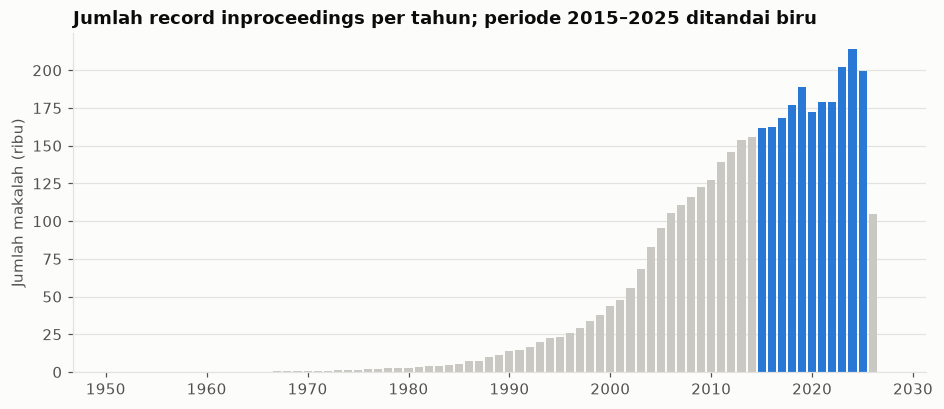

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
n_records,161509,162422,168310,176866,189014,172238,178987,178705,201924,213856,199448


In [9]:
per_year = inproc["year"].value_counts().sort_index()
colors = [SERIES[0] if config.YEAR_MIN <= y <= config.YEAR_MAX else MUTED_FILL for y in per_year.index]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(per_year.index, per_year.values / 1e3, color=colors, width=0.8)
ax.set_ylabel("Jumlah makalah (ribu)")
ax.set_title("Jumlah record inproceedings per tahun; periode 2015–2025 ditandai biru")
ax.grid(axis="x", visible=False)
save(fig, "01_inproceedings_per_year")
plt.show()
per_year.loc[config.YEAR_MIN:config.YEAR_MAX].to_frame("n_records").T

Distribusi prefix `key` dan record di luar prefix `conf/`.

In [10]:
pd.DataFrame({
    "semua tahun": inproc["prefix"].value_counts(),
    "2015–2025": inproc.loc[in_period, "prefix"].value_counts(),
}).fillna(0).astype(int)

,semua tahun,2015–2025
prefix,,
books,51,40
conf,3980692,2000116
journals,14138,3123
persons,1,0
series,57,0
www,1,0


In [11]:
inproc.loc[inproc["prefix"] == "journals", "key"].str.rsplit("/", n=1).str[0].value_counts().head(8).to_frame("n_records")

,n_records
key,
journals/entcs,5833
journals/corr,4453
journals/procedia,2013
journals/jmlr,938
journals/oopsm,257
journals/sigplan,204
journals/tcs,142
journals/sigmetrics,107


Distribusi atribut `publtype` (`withdrawn` = makalah ditarik, `informal` = publikasi informal).

In [12]:
pd.DataFrame({
    "semua tahun": inproc["publtype"].value_counts(dropna=False),
    "2015–2025": inproc.loc[in_period, "publtype"].value_counts(dropna=False),
}).fillna(0).astype(int)

,semua tahun,2015–2025
publtype,,
edited,2,2
informal,4034,427
informal withdrawn,1,1
withdrawn,1960,1123
NaN,3988943,2001726


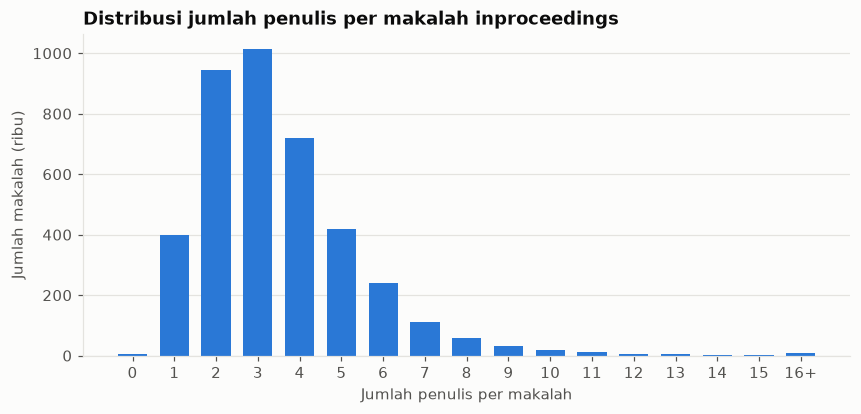

,count,mean,std,min,25%,50%,75%,max
n_authors,3994940.0,3.5,2.11,0.0,2.0,3.0,4.0,279.0


In [13]:
capped = inproc["n_authors"].clip(upper=16)
dist = capped.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(dist.index, dist.values / 1e3, color=SERIES[0], width=0.7)
ax.set_xticks(dist.index, [str(i) if i < 16 else "16+" for i in dist.index])
ax.set_xlabel("Jumlah penulis per makalah")
ax.set_ylabel("Jumlah makalah (ribu)")
ax.set_title("Distribusi jumlah penulis per makalah inproceedings")
ax.grid(axis="x", visible=False)
save(fig, "01_authors_per_paper")
plt.show()
inproc["n_authors"].describe().round(2).to_frame("n_authors").T